# Notebook 03 · Word2Vec del dominio hotelero y proyecciones semánticas

**Autores:** Isabel Cristina Morales Parra – Jaime Esteban Bejarano Caldas

**Objetivos que cubre:** objetivo 3 (clasificación con Word2Vec, comparada con TF-IDF), objetivo 4 (evaluación intrínseca del espacio vectorial) y objetivo 5 (dimensiones del servicio mediante proyecciones semánticas).

## 0. Entrenamiento de Word2Vec

Se entrena un modelo Word2Vec propio del dominio (Mikolov et al., 2013) con la arquitectura **skip-gram**, que aprende a predecir las palabras del contexto a partir de la palabra central. Skip-gram representa mejor las palabras poco frecuentes que la arquitectura CBOW, lo que es conveniente en un corpus pequeño.

**El modelo se entrena solo con las reseñas de entrenamiento** (la misma partición del notebook 02). Si se incluyeran las reseñas de prueba, los vectores habrían «visto» esos textos y la comparación con TF-IDF no sería justa.

| Hiperparámetro | Valor | Significado |
|:--|:--|:--|
| `vector_size` | 100 | Dimensión de cada vector |
| `window` | 5 | Palabras de contexto a cada lado |
| `min_count` | 5 | Se ignoran las palabras con menos de 5 apariciones (elimina *hapax* y errores de digitación) |
| `sg` | 1 | Skip-gram |
| `negative` | 10 | *Negative sampling*: en cada paso se contrastan 10 palabras al azar que no son del contexto |
| `epochs` | 10 | Pasadas completas por el corpus |

In [2]:
%load_ext autoreload
%autoreload 2

import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.append(str(RAIZ))
from src.evaluacion import metricas_clasificacion
from src.representaciones import matriz_resenas

RUTA_FIGURAS = RAIZ / "figures"
RUTA_RESULTADOS = RAIZ / "results"
RUTA_MODELOS = RAIZ / "models"
RUTA_MODELOS.mkdir(exist_ok=True)
SEMILLA = 42
sns.set_theme(style="whitegrid", palette="deep")

# --- Misma partición que el notebook 02 ---
df_en = pd.read_csv(RAIZ / "data" / "processed" / "resenas_en_depuradas.csv")
corpus_A = df_en.dropna(subset=["polaridad_A"]).reset_index(drop=True)
X_entrena, X_prueba, y_entrena, y_prueba = train_test_split(
    corpus_A["texto_limpio"], corpus_A["polaridad_A"],
    test_size=0.20, stratify=corpus_A["polaridad_A"], random_state=SEMILLA)

indices_02 = pd.read_csv(RUTA_RESULTADOS / "02_indices_prueba.csv")["indice"]
print("¿Misma partición que el notebook 02?", set(indices_02) == set(X_prueba.index))

# --- Entrenamiento ---
frases = [texto.split() for texto in X_entrena]
inicio = time.perf_counter()
w2v = Word2Vec(sentences=frases, vector_size=100, window=5, min_count=5, sg=1,
               negative=10, epochs=10, seed=SEMILLA, workers=1)
print(f"Tiempo de entrenamiento: {time.perf_counter() - inicio:.0f} s")
print(f"Vocabulario del modelo: {len(w2v.wv):,} palabras")
w2v.save(str(RUTA_MODELOS / "word2vec_hoteles.model"))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
¿Misma partición que el notebook 02? True
Tiempo de entrenamiento: 31 s
Vocabulario del modelo: 5,322 palabras


**Resultado.** La partición es idéntica a la del notebook 02 (`True`), lo que garantiza que Word2Vec y TF-IDF se evaluarán sobre las mismas 3.288 reseñas de prueba. El modelo se entrenó en 31 segundos con las 13.150 reseñas de entrenamiento y aprendió vectores para **5.322 palabras**: las que aparecen al menos 5 veces. Eso es menos de una cuarta parte de los 22.931 tipos del corpus normalizado. Las demás palabras (*hapax*, errores de digitación, nombres raros) no tienen vector y se ignorarán al representar cada reseña.

## 1. Evaluación intrínseca del espacio vectorial

Antes de usar los vectores para clasificar, se verifica que hayan capturado relaciones semánticas del dominio. Se hacen cuatro pruebas:
1. **Vecinos más cercanos:** las palabras con mayor similitud coseno a una palabra dada deberían estar relacionadas con ella.
2. **Analogías:** la aritmética vectorial *a − b + c ≈ d* (por ejemplo, *kathmandu − city + lake*) debería devolver una palabra que complete la relación.
3. **Término discordante (*odd one out*):** en un grupo de palabras, el modelo debe identificar la que no pertenece.
4. **Visualización con PCA:** al proyectar los vectores a 2 dimensiones, las palabras del mismo campo semántico deberían agruparse.

1. VECINOS MÁS CERCANOS (similitud coseno)


,Vecino 1,Vecino 2,Vecino 3,Vecino 4,Vecino 5
staff,exceedingly (0.76),graceful (0.76),fantastically (0.75),loving (0.74),amiable (0.74)
breakfast,brekkie (0.74),comprehensive (0.72),buffet (0.71),repetitive (0.69),café (0.67)
dirty,filthy (0.78),mould (0.75),stain (0.75),smelly (0.75),dingy (0.74)
rude,incident (0.74),ignore (0.73),unprofessional (0.72),rudely (0.72),secondly (0.72)
spa,sauna (0.74),massage (0.74),facial (0.72),steam (0.71),workout (0.71)
view,panaromic (0.78),machhapuchre (0.75),skyline (0.75),seventh (0.75),machhapuchhre (0.75)
refund,confirmation (0.84),cancellation (0.84),error (0.84),agoda (0.83),payment (0.83)
pool,swimming (0.75),unheated (0.74),pavilion (0.72),swim (0.72),sunbed (0.71)


2. ANALOGÍAS


,Analogía,Esperada,Top 3 del modelo
0,kathmandu − city + lake,phewa,"phewa, begnas, tal"
1,dinner − night + morning,breakfast/brekkie,"fresco, brekkie, dessert"
2,clean − good + bad,dirty,"terrible, leak, cigarette"


3. TÉRMINO DISCORDANTE


,Grupo,Discordante según el modelo
0,"breakfast, dinner, lunch, pool",pool
1,"rude, dirty, friendly, noisy",friendly
2,"kathmandu, pokhara, chitwan, towel",towel
3,"refund, bill, charge, sunset",sunset


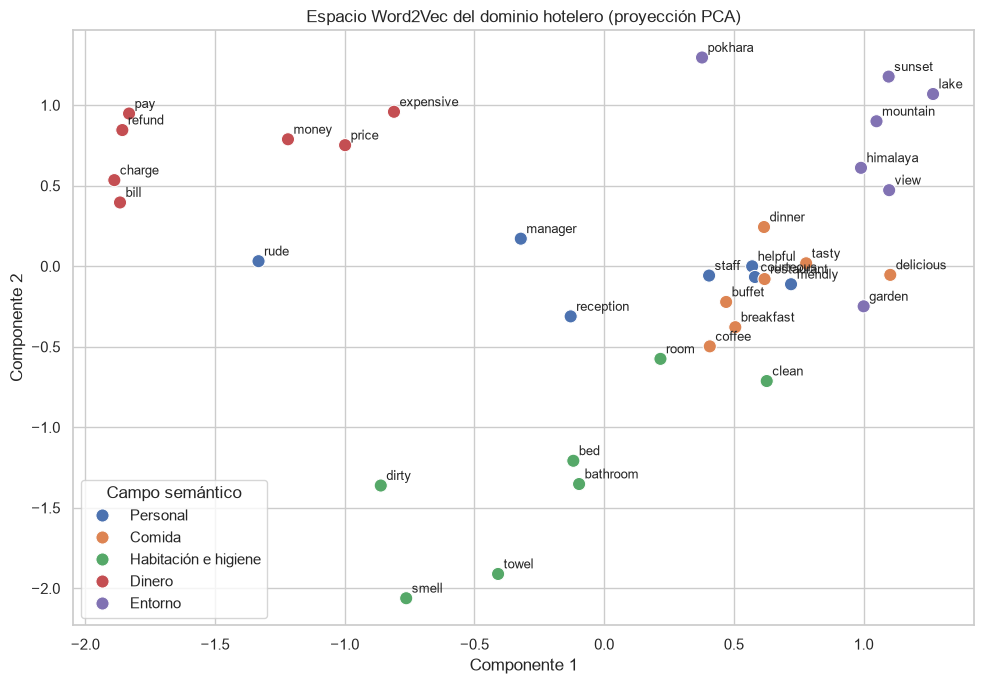

In [3]:
from sklearn.decomposition import PCA

wv = w2v.wv

# --- 1. Vecinos más cercanos ---
palabras_prueba = ["staff", "breakfast", "dirty", "rude", "spa", "view", "refund", "pool"]
vecinos = pd.DataFrame({p: [f"{v} ({s:.2f})" for v, s in wv.most_similar(p, topn=5)] for p in palabras_prueba})
vecinos.index = [f"Vecino {i}" for i in range(1, 6)]
print("1. VECINOS MÁS CERCANOS (similitud coseno)")
display(vecinos.T)

# --- 2. Analogías: a − b + c ---
analogias = [  # (positivas, negativas, respuesta esperada)
    (["kathmandu", "lake"], ["city"], "phewa"),
    (["dinner", "morning"], ["night"], "breakfast/brekkie"),
    (["clean", "bad"], ["good"], "dirty"),
]
filas = []
for positivas, negativas, esperada in analogias:
    top3 = [v for v, _ in wv.most_similar(positive=positivas, negative=negativas, topn=3)]
    filas.append({"Analogía": f"{positivas[0]} − {negativas[0]} + {positivas[1]}",
                  "Esperada": esperada, "Top 3 del modelo": ", ".join(top3)})
print("2. ANALOGÍAS")
display(pd.DataFrame(filas))

# --- 3. Término discordante ---
grupos = [["breakfast", "dinner", "lunch", "pool"],
          ["rude", "dirty", "friendly", "noisy"],
          ["kathmandu", "pokhara", "chitwan", "towel"],
          ["refund", "bill", "charge", "sunset"]]
print("3. TÉRMINO DISCORDANTE")
display(pd.DataFrame({"Grupo": [", ".join(g) for g in grupos],
                      "Discordante según el modelo": [wv.doesnt_match(g) for g in grupos]}))

# --- 4. PCA por campos semánticos ---
campos = {
    "Personal": ["staff", "friendly", "helpful", "rude", "manager", "reception", "courteous"],
    "Comida": ["breakfast", "dinner", "buffet", "delicious", "restaurant", "coffee", "tasty"],
    "Habitación e higiene": ["room", "clean", "dirty", "bathroom", "bed", "smell", "towel"],
    "Dinero": ["price", "bill", "charge", "refund", "expensive", "pay", "money"],
    "Entorno": ["view", "mountain", "lake", "pokhara", "garden", "sunset", "himalaya"],
}
palabras = [p for lista in campos.values() for p in lista]
etiquetas = [campo for campo, lista in campos.items() for _ in lista]
coords = PCA(n_components=2, random_state=SEMILLA).fit_transform(wv[palabras])

fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=etiquetas, s=90, ax=ax)
for (x, y), palabra in zip(coords, palabras):
    ax.annotate(palabra, (x, y), xytext=(4, 4), textcoords="offset points", fontsize=9)
ax.set(title="Espacio Word2Vec del dominio hotelero (proyección PCA)", xlabel="Componente 1", ylabel="Componente 2")
ax.legend(title="Campo semántico")
plt.tight_layout()
fig.savefig(RUTA_FIGURAS / "03_word2vec_pca.png", dpi=150, bbox_inches="tight")
plt.show()

vecinos.T.to_csv(RUTA_RESULTADOS / "03_vecinos_word2vec.csv")

**Resultado de la evaluación intrínseca.**

**1. Vecinos más cercanos: el espacio capturó relaciones del dominio.**
- ***dirty*** → *filthy, mould, stain, smelly, dingy*: sinónimos y causas concretas de la suciedad.
- ***spa*** → *sauna, massage, facial, steam*; ***pool*** → *swimming, unheated, sunbed*.
- ***refund*** → *confirmation, cancellation, error, agoda, payment*: el vocabulario de las disputas por reservas, incluida una plataforma de reservas (Agoda).
- ***view*** → *panaromic, machhapuchre, machhapuchhre*: el modelo agrupa **variantes ortográficas** del monte Machapuchare. Es una ventaja frente a BoW, que trataría cada variante como una palabra distinta.
- ***staff*** → *exceedingly, graceful, fantastically, loving*: los vecinos no son sinónimos de *staff*, sino **lo que se dice del personal**. Word2Vec aprende de los contextos en que aparece cada palabra, y el personal aparece casi siempre en contextos de elogio.
- ***breakfast*** → *buffet, café* y también *repetitive*, una queja habitual sobre el desayuno.

**2. Analogías: éxito parcial.** *kathmandu − city + lake* devuelve ***phewa***: el lago Phewa de Pokhara, en la primera posición. *dinner − night + morning* devuelve *brekkie* (desayuno) en segunda posición. *clean − good + bad* devuelve *terrible* en lugar de *dirty*: el modelo capturó la inversión de polaridad, pero no la especificidad del campo higiene. Las analogías funcionan mejor para relaciones frecuentes en el corpus.

**3. Término discordante: 4 de 4 aciertos** (*pool*, *friendly*, *towel*, *sunset*).

**4. PCA.** Las palabras de cada campo semántico tienden a agruparse: el dinero arriba a la izquierda, el entorno arriba a la derecha, la habitación abajo. Además, **el componente 1 separa la valoración**: *rude*, *dirty*, *smell* y el campo del dinero quedan a la izquierda; *friendly*, *delicious* y el entorno, a la derecha. Dentro del campo «Personal», *rude* y *friendly* quedan en extremos opuestos. La polaridad es una de las direcciones principales del espacio, lo que anticipa la viabilidad de las proyecciones semánticas (sección 4).

## 2. Clasificación con Word2Vec y curva de aprendizaje

Cada reseña se representa con el **promedio de los vectores Word2Vec** de sus palabras, en dos variantes: promedio simple y **promedio ponderado por IDF**, que da más peso a las palabras raras e informativas. Se usa la misma regresión logística, el mismo ajuste de `C` y la misma partición que en el notebook 02.

**Curva de aprendizaje (extensión experimental).** Se modifica una sola condición: el número de reseñas **etiquetadas** disponibles para entrenar el clasificador (de 250 a 13.150), y se mide el F1-macro de TF-IDF y Word2Vec sobre el mismo conjunto de prueba. Para cada tamaño se promedian 3 submuestras estratificadas. Los vectores Word2Vec se mantienen fijos: se aprendieron sin etiquetas con todo el conjunto de entrenamiento. La pregunta es: **¿qué representación conviene cuando hay pocas reseñas etiquetadas?**

,F1-macro,Exactitud balanceada,Precisión (negativo),Recall (negativo),F1-macro (validación cruzada)
Línea base,0.490,0.500,0.000,0.000,NaN
BoW binario,0.884,0.916,0.719,0.846,0.877
BoW conteos,0.886,0.891,0.769,0.792,0.884
TF-IDF (1–2),0.918,0.927,0.824,0.862,0.904
Word2Vec (promedio),0.806,0.945,0.482,0.931,0.796
Word2Vec (promedio IDF),0.790,0.945,0.447,0.938,0.782


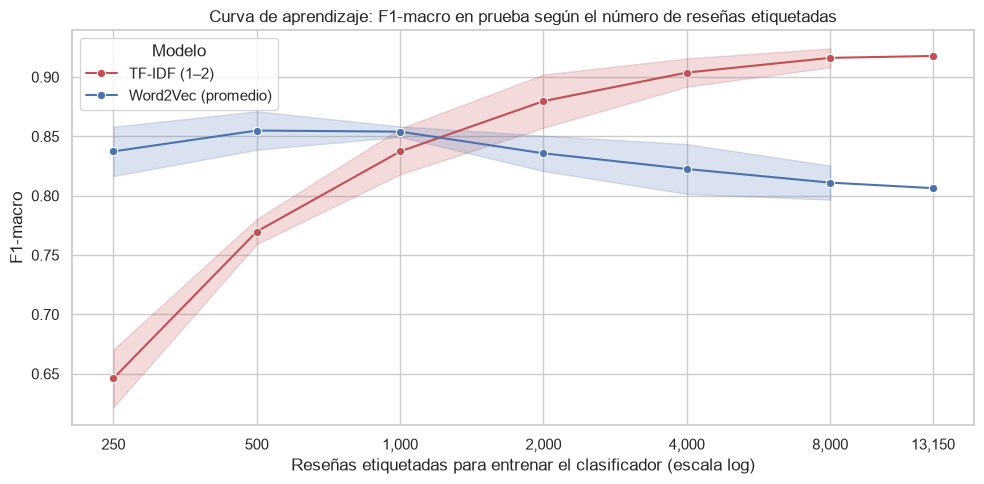

Modelo,TF-IDF (1–2),Word2Vec (promedio)
Reseñas etiquetadas,,
250,0.646,0.837
500,0.770,0.855
1000,0.837,0.854
2000,0.880,0.836
4000,0.904,0.823
8000,0.916,0.811
13150,0.918,0.806


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

# --- Vectores de reseña ---
idf = TfidfVectorizer(token_pattern=r"\S+").fit(X_entrena)          # IDF aprendido solo en entrenamiento
pesos_idf = dict(zip(idf.get_feature_names_out(), idf.idf_))

variantes = {
    "Word2Vec (promedio)": (matriz_resenas(X_entrena, wv), matriz_resenas(X_prueba, wv)),
    "Word2Vec (promedio IDF)": (matriz_resenas(X_entrena, wv, pesos_idf), matriz_resenas(X_prueba, wv, pesos_idf)),
}

resultados_w2v = {}
for nombre, (A_entrena, A_prueba) in variantes.items():
    busqueda = GridSearchCV(LogisticRegression(class_weight="balanced", max_iter=5000),
                            {"C": [0.1, 0.3, 1, 3, 10, 30, 100]}, scoring="f1_macro", cv=validacion, n_jobs=-1)
    busqueda.fit(A_entrena, y_entrena)
    resultados_w2v[nombre] = metricas_clasificacion(y_prueba, busqueda.predict(A_prueba))
    resultados_w2v[nombre].update({"F1-macro (validación cruzada)": busqueda.best_score_,
                                   "C elegido": busqueda.best_params_["C"]})

# --- Tabla comparativa con el notebook 02 ---
tabla_02 = pd.read_csv(RUTA_RESULTADOS / "02_comparacion_representaciones_dispersas.csv", index_col=0)
columnas = ["F1-macro", "Exactitud balanceada", "Precisión (negativo)", "Recall (negativo)", "F1-macro (validación cruzada)"]
comparacion = pd.concat([tabla_02[columnas], pd.DataFrame(resultados_w2v).T[columnas]])
display(comparacion.astype(float).round(3))
comparacion.to_csv(RUTA_RESULTADOS / "03_comparacion_todas_las_representaciones.csv")

# --- Curva de aprendizaje: TF-IDF frente a Word2Vec ---
A_entrena, A_prueba = variantes["Word2Vec (promedio)"]
tamanos = [250, 500, 1000, 2000, 4000, 8000, len(X_entrena)]
filas = []
for n in tamanos:
    for repeticion in range(3 if n < len(X_entrena) else 1):
        if n < len(X_entrena):
            idx, _ = train_test_split(np.arange(len(X_entrena)), train_size=n,
                                      stratify=y_entrena, random_state=SEMILLA + repeticion)
        else:
            idx = np.arange(len(X_entrena))
        tfidf = Pipeline([
            ("representacion", TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True, token_pattern=r"\S+")),
            ("clasificador", LogisticRegression(class_weight="balanced", solver="liblinear", C=30, max_iter=2000)),
        ]).fit(X_entrena.iloc[idx], y_entrena.iloc[idx])
        w2v_clf = LogisticRegression(class_weight="balanced", C=30, max_iter=5000).fit(A_entrena[idx], y_entrena.iloc[idx])
        filas += [{"Reseñas etiquetadas": n, "Modelo": "TF-IDF (1–2)", "F1-macro": f1_score(y_prueba, tfidf.predict(X_prueba), average="macro")},
                  {"Reseñas etiquetadas": n, "Modelo": "Word2Vec (promedio)", "F1-macro": f1_score(y_prueba, w2v_clf.predict(A_prueba), average="macro")}]

curva = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=curva, x="Reseñas etiquetadas", y="F1-macro", hue="Modelo", marker="o",
             errorbar="sd", palette=["#C44E52", "#4C72B0"], ax=ax)
ax.set(xscale="log", title="Curva de aprendizaje: F1-macro en prueba según el número de reseñas etiquetadas",
       xlabel="Reseñas etiquetadas para entrenar el clasificador (escala log)")
ax.set_xticks(tamanos)
ax.set_xticklabels([f"{t:,}" for t in tamanos])
plt.tight_layout()
fig.savefig(RUTA_FIGURAS / "03_curva_aprendizaje.png", dpi=150, bbox_inches="tight")
plt.show()

display(curva.groupby(["Reseñas etiquetadas", "Modelo"])["F1-macro"].mean().unstack().round(3))
curva.to_csv(RUTA_RESULTADOS / "03_curva_aprendizaje.csv", index=False)

**Resultado 1: con el conjunto completo, TF-IDF supera a Word2Vec en F1-macro** (0,918 frente a 0,806). Pero los dos modelos cometen errores distintos:

| Modelo | *Recall* negativo | Precisión negativa | Exactitud balanceada |
|:--|--:|--:|--:|
| TF-IDF (1–2) | 0,862 | **0,824** | 0,927 |
| Word2Vec (promedio) | **0,931** | 0,482 | **0,945** |

Word2Vec detecta más reseñas negativas (121 de 130, frente a 112), pero a costa de muchas falsas alarmas: menos de la mitad de las reseñas que marca como negativas lo son. Cuál conviene depende del uso. Para un sistema de alerta de quejas que un humano revisa después, el mayor *recall* de Word2Vec puede ser preferible; para clasificar automáticamente sin revisión, la precisión de TF-IDF es más adecuada.

**Resultado 2: la ponderación por IDF no mejora a Word2Vec** (F1-macro 0,790 frente a 0,806). Al dar más peso a las palabras raras, se amplifica el ruido de términos poco frecuentes cuyos vectores están peor estimados.

**Resultado 3: la curva de aprendizaje confirma la hipótesis del anteproyecto.** Con pocas reseñas etiquetadas, **Word2Vec es claramente superior**: 0,837 frente a 0,646 con 250 reseñas, y 0,855 frente a 0,770 con 500. Las curvas se cruzan alrededor de 1.000 reseñas; a partir de 2.000, TF-IDF domina. La explicación es que Word2Vec aprende la semántica **sin etiquetas** (de todo el corpus de entrenamiento), así que el clasificador solo necesita aprender 100 coeficientes. TF-IDF, en cambio, debe aprender un coeficiente por cada término del vocabulario a partir de las etiquetas, y para eso necesita muchos ejemplos.

**Por qué Word2Vec no mejora con más datos** (hipótesis): el promedio de vectores **pierde el orden de las palabras y diluye la negación**. *not clean* se representa como el promedio de *not* y *clean*, muy parecido al de *clean* solo. Con 100 dimensiones, el modelo lineal alcanza su techo con pocas reseñas, mientras que los bigramas de TF-IDF capturan *not clean* de forma explícita. La leve caída del F1 con más datos se asocia a la pérdida de precisión: el modelo marca más reseñas como negativas a medida que crece el entrenamiento. Esta hipótesis no se verificó en este trabajo.

**Implicación práctica:** para un hotel que empieza a etiquetar sus reseñas, Word2Vec ofrece un buen clasificador con pocos cientos de ejemplos; cuando se dispone de miles, TF-IDF con bigramas es la mejor opción.

*Simplificación declarada:* en la curva de aprendizaje se fijó `C = 30` para todos los tamaños, en lugar de reajustarlo en cada uno.

## 3. Proyecciones semánticas: dimensiones del servicio

Una **proyección semántica** mide la posición de un texto sobre una dirección del espacio vectorial definida por palabras ancla. Por ejemplo, el eje de *atención del personal* va desde {*rude, unprofessional, unfriendly…*} hasta {*friendly, helpful, courteous…*}. La puntuación es la similitud coseno entre el vector del texto y el eje: positiva si el texto se acerca al polo favorable, negativa si se acerca al desfavorable.

Se definen cinco dimensiones del servicio, cada una con un eje (palabras ancla) y unos **términos de aspecto** que indican que la reseña habla de esa dimensión:

| Dimensión | Polo favorable | Polo desfavorable | Términos de aspecto |
|:--|:--|:--|:--|
| Personal | friendly, helpful, courteous… | rude, unprofessional, arrogant… | staff, service, reception… |
| Limpieza | clean, spotless, tidy… | dirty, filthy, smelly… | room, bathroom, bed… |
| Comida | delicious, tasty, yummy… | bland, tasteless, stale… | food, breakfast, dinner… |
| Precio | worth, reasonable, affordable… | overprice, expensive, overcharge… | price, cost, money, bill… |
| Instalaciones | new, modern, spacious… | old, broken, outdated… | building, pool, facility… |

Se comparan dos métodos:
1. **Proyección global:** el vector completo de la reseña sobre cada eje.
2. **Proyección por aspecto:** solo las palabras que rodean (± 4 posiciones) a los términos del aspecto. Si la reseña no menciona el aspecto, no recibe puntuación.

Para cada dimensión se calcula la correlación de Spearman con la calificación y el **tamaño del efecto (d de Cohen)** entre reseñas negativas y positivas.

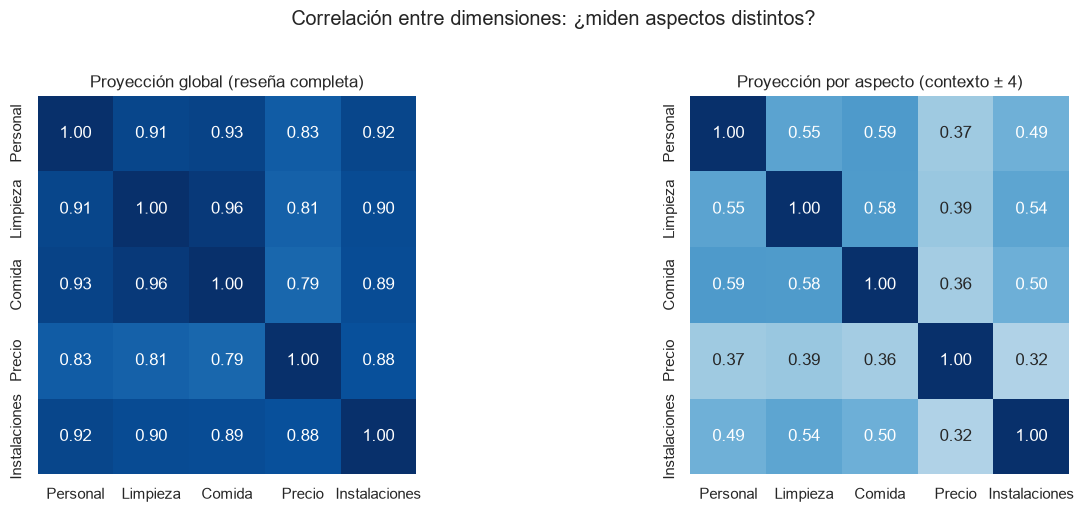

,% reseñas que la mencionan,% negativas que la mencionan,Spearman con Rating,d de Cohen (pos − neg),Media en negativas,Media en positivas
Dimensión,,,,,,
Personal,80.160,71.077,0.350,2.715,-0.060,0.230
Limpieza,51.086,70.462,0.477,2.031,-0.104,0.144
Comida,70.231,56.769,0.434,2.223,-0.041,0.192
Precio,10.890,39.692,0.391,0.933,0.074,0.167
Instalaciones,35.984,43.231,0.426,1.824,-0.055,0.123


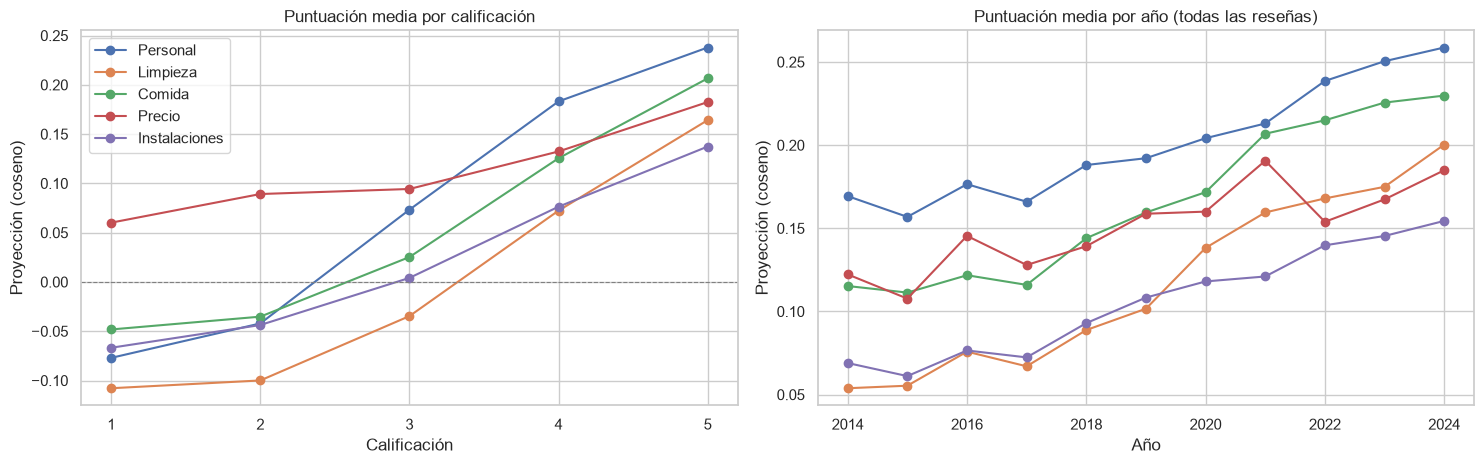

In [5]:
from scipy.stats import spearmanr
from src.proyecciones import eje_semantico, proyeccion_global, proyeccion_aspecto

dimensiones = {
    "Personal": (["friendly", "helpful", "courteous", "attentive", "polite", "welcoming"],
                 ["rude", "unprofessional", "unfriendly", "arrogant", "ignore", "unhelpful"],
                 ["staff", "service", "reception", "manager", "employee", "waiter"]),
    "Limpieza": (["clean", "spotless", "tidy", "hygienic", "fresh", "neat"],
                 ["dirty", "filthy", "smelly", "stain", "dusty", "mould"],
                 ["room", "bathroom", "bed", "toilet", "towel", "sheet"]),
    "Comida": (["delicious", "tasty", "yummy", "excellent", "variety", "fresh"],
               ["bland", "tasteless", "stale", "repetitive", "cold", "limited"],
               ["food", "breakfast", "dinner", "buffet", "restaurant", "meal"]),
    "Precio": (["worth", "reasonable", "affordable", "value", "fair", "cheap"],
               ["overprice", "expensive", "overcharge", "overrate", "pricey", "rip"],
               ["price", "cost", "rate", "money", "bill", "charge"]),
    "Instalaciones": (["new", "modern", "renovate", "spacious", "comfortable", "luxurious"],
                      ["old", "broken", "outdated", "leak", "noisy", "damage"],
                      ["building", "pool", "facility", "furniture", "gym", "lobby", "property", "wifi", "ac", "lift"]),
}

ejes = {dim: eje_semantico(wv, pos, neg) for dim, (pos, neg, _) in dimensiones.items()}
matriz_todas = matriz_resenas(df_en["texto_limpio"], wv)

global_df = pd.DataFrame({dim: proyeccion_global(matriz_todas, eje) for dim, eje in ejes.items()})
aspecto_df = pd.DataFrame({dim: [proyeccion_aspecto(t, wv, set(dimensiones[dim][2]), ejes[dim])
                                 for t in df_en["texto_limpio"]] for dim in dimensiones})

# --- Figura 1: correlación entre dimensiones con cada método ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (titulo, datos) in zip(axes, [("Proyección global (reseña completa)", global_df),
                                      ("Proyección por aspecto (contexto ± 4)", aspecto_df)]):
    sns.heatmap(datos.corr(), annot=True, fmt=".2f", vmin=0, vmax=1, cmap="Blues", square=True, cbar=False, ax=ax)
    ax.set_title(titulo)
plt.suptitle("Correlación entre dimensiones: ¿miden aspectos distintos?", y=1.02)
plt.tight_layout()
fig.savefig(RUTA_FIGURAS / "03_proyecciones_correlacion_metodos.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Tabla: relación de cada dimensión (por aspecto) con la calificación ---
calificacion = df_en["Rating"]
filas = []
for dim in dimensiones:
    s = aspecto_df[dim]
    valida = s.notna()
    neg = s[valida & (calificacion <= 2)]
    pos = s[valida & (calificacion >= 4)]
    filas.append({
        "Dimensión": dim,
        "% reseñas que la mencionan": valida.mean() * 100,
        "% negativas que la mencionan": neg.size / (calificacion <= 2).sum() * 100,
        "Spearman con Rating": spearmanr(s[valida], calificacion[valida])[0],
        "d de Cohen (pos − neg)": (pos.mean() - neg.mean()) / np.sqrt((pos.var() + neg.var()) / 2),
        "Media en negativas": neg.mean(),
        "Media en positivas": pos.mean(),
    })
tabla_dim = pd.DataFrame(filas).set_index("Dimensión")
display(tabla_dim.round(3))
tabla_dim.to_csv(RUTA_RESULTADOS / "03_dimensiones_servicio.csv")

# --- Figura 2: puntuación por calificación y por año ---
puntajes = aspecto_df.assign(Rating=df_en["Rating"], anio=df_en["anio"])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
puntajes.groupby("Rating")[list(dimensiones)].mean().plot(marker="o", ax=axes[0])
axes[0].axhline(0, color="gray", lw=0.8, ls="--")
axes[0].set(title="Puntuación media por calificación", xlabel="Calificación", ylabel="Proyección (coseno)")
axes[0].set_xticks([1, 2, 3, 4, 5])
puntajes.groupby("anio")[list(dimensiones)].mean().plot(marker="o", ax=axes[1], legend=False)
axes[1].set(title="Puntuación media por año (todas las reseñas)", xlabel="Año", ylabel="Proyección (coseno)")
plt.tight_layout()
fig.savefig(RUTA_FIGURAS / "03_dimensiones_servicio.png", dpi=150, bbox_inches="tight")
plt.show()

puntajes.to_csv(RUTA_RESULTADOS / "03_puntajes_dimensiones.csv", index=False)

**Resultado metodológico: la proyección global no distingue aspectos.** Con el vector completo de la reseña, las cinco dimensiones están correlacionadas entre 0,79 y 0,96: todas miden el **sentimiento general**. Una reseña elogiosa puntúa alto en «limpieza» aunque no hable de limpieza. Al proyectar solo el contexto del aspecto, las correlaciones bajan a 0,32–0,59 y cada dimensión captura algo distinto. **Para medir dimensiones del servicio no basta con definir el eje: hay que delimitar qué parte del texto se proyecta.**

**Resultado sustantivo: qué dimensiones se asocian a las experiencias negativas.**

| Dimensión | Mencionada en todas | Mencionada en negativas | d de Cohen | Media en negativas |
|:--|--:|--:|--:|--:|
| Personal | 80,2 % | 71,1 % | **2,72** | −0,060 |
| Limpieza | 51,1 % | **70,5 %** | 2,03 | **−0,104** |
| Comida | 70,2 % | 56,8 % | 2,22 | −0,041 |
| Precio | 10,9 % | **39,7 %** | 0,93 | +0,074 |
| Instalaciones | 36,0 % | 43,2 % | 1,82 | −0,055 |

1. **El personal es la dimensión que más separa las experiencias positivas de las negativas** (d = 2,72): es la más mencionada y la que más cambia entre clases. En un hotel de lujo, el trato define la experiencia.
2. **La limpieza es el aspecto peor valorado en las reseñas negativas** (media −0,104) y está **sobrerrepresentado** en ellas: la menciona el 51 % del corpus, pero el 70 % de las negativas. Coincide con *dirty* y *stain* entre los términos distintivos del notebook 01.
3. **El precio casi no se menciona en general (11 %), pero aparece en el 40 % de las reseñas negativas**: 3,6 veces más. Es el aspecto más específico de la insatisfacción. Sin embargo, su proyección sigue siendo positiva incluso en reseñas de 1 estrella (+0,06) y separa poco las clases (d = 0,93). La explicación probable es que las quejas sobre dinero en este corpus no tratan de lo caro (*expensive*), sino de **cobros y reembolsos** (*refund*, *bill*, *charge*: notebook 01), un vocabulario que el eje *worth – overprice* no captura. **Limitación:** el resultado de una proyección depende de la elección de las palabras ancla.
4. **Evolución temporal.** Las cinco dimensiones mejoran entre 2014 y 2024, coherente con el aumento de la calificación promedio. Limpieza e instalaciones son las que más suben (de ≈ 0,05–0,07 a 0,15–0,20). Como ya se advirtió, este aumento no prueba una mejora del servicio, porque el conjunto de datos no permite separarla de cambios en los hoteles reseñados o en la plataforma.

*Nota:* Word2Vec se entrenó con el conjunto de entrenamiento; las proyecciones se calculan sobre todo el corpus con fines descriptivos, no predictivos.